(891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
             count unique                      top freq       mean  \
PassengerId  891.0    NaN                      NaN  NaN      446.0   
Survived     891.0    NaN                      NaN  NaN   0.383838   
Pclass       891.0    NaN                      NaN  NaN   2.308642   
Name           891    891  Braund, Mr. Owen Harris    1        NaN   
Sex            891      2                     male  577        NaN   
Age          714.0    NaN              

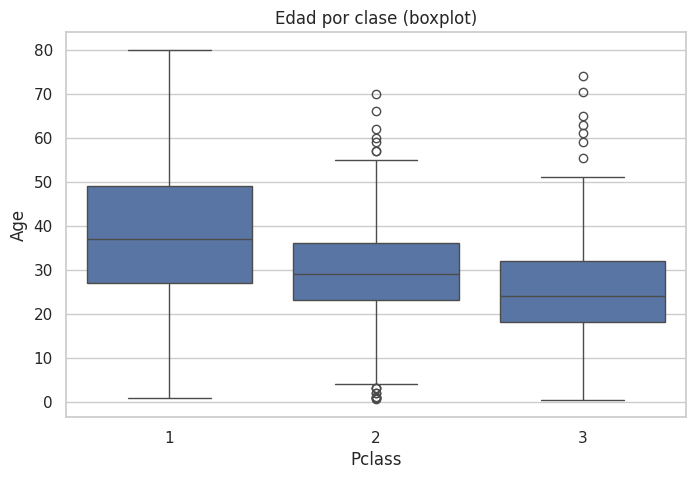

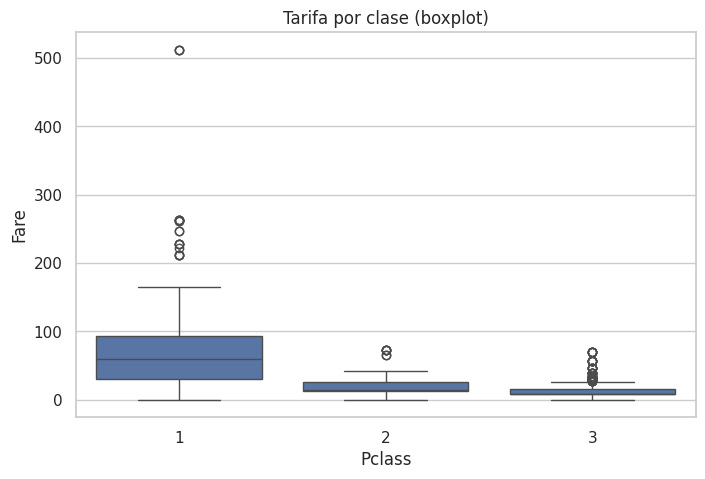

Age: 11 outliers
Fare: 116 outliers


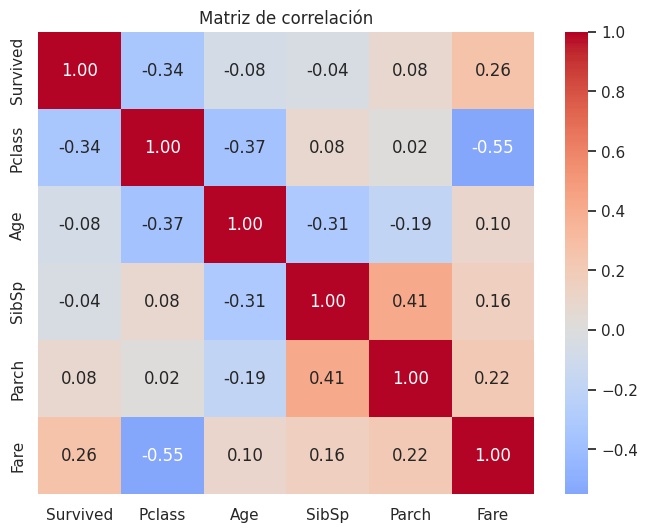

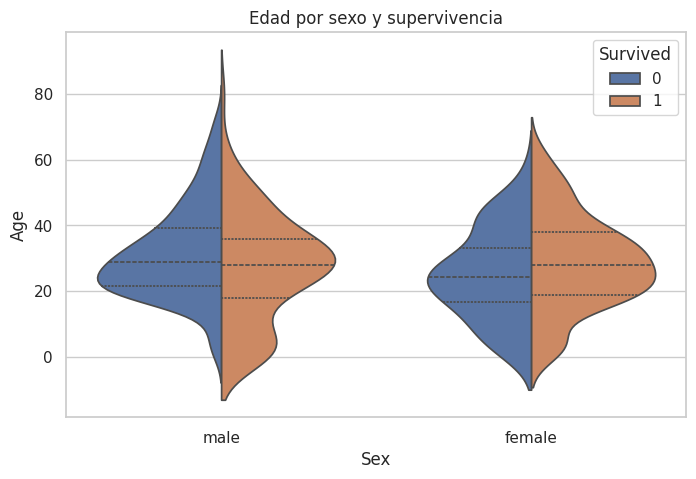

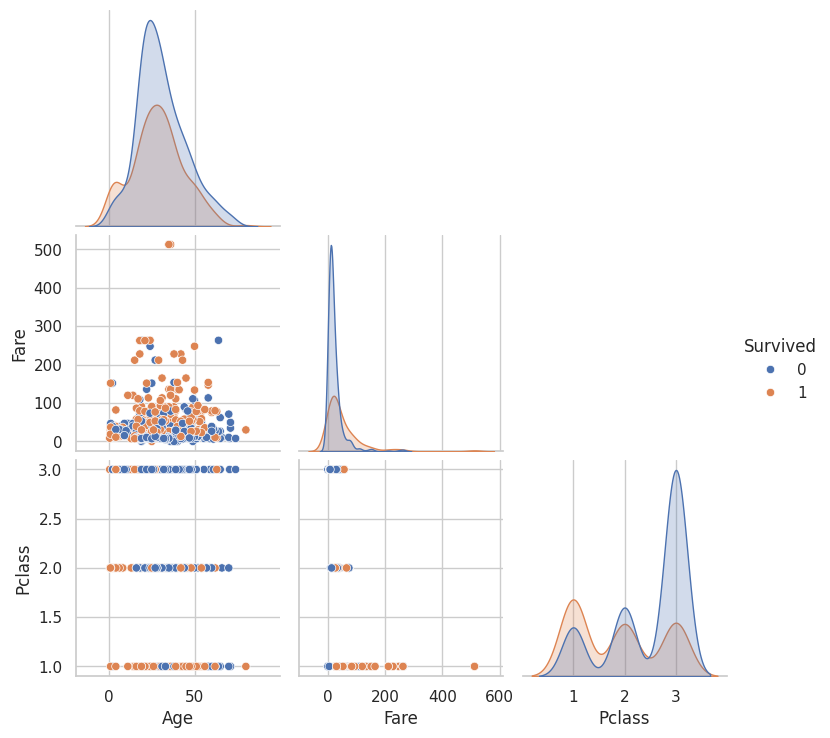

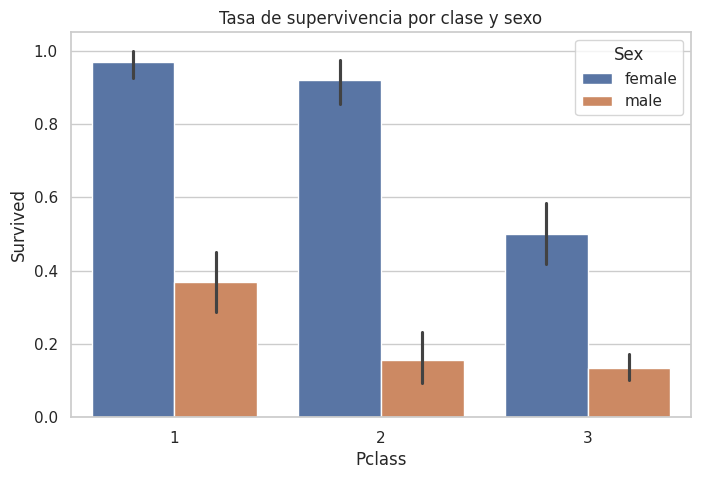

In [1]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt

df = pd.read_csv("train.csv")
sns.set_theme(style="whitegrid")

# --- Exploración básica ---
print(df.shape)
print(df.dtypes)
print(df.isna().sum())
print(df.describe(include="all").T)
print("Duplicados:", df.duplicated().sum())

num = ["Age", "Fare", "SibSp", "Parch"]

# 1) Diagrama de cajas y bigotes: Edad por clase
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Pclass", y="Age")
plt.title("Edad por clase (boxplot)"); plt.show()

# 1b) Boxplot de Fare por clase
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Pclass", y="Fare")
plt.title("Tarifa por clase (boxplot)"); plt.show()

# Outliers por IQR
for c in ["Age", "Fare"]:
    q1, q3 = df[c].quantile([.25, .75]); i = q3 - q1
    n = ((df[c] < q1-1.5*i) | (df[c] > q3+1.5*i)).sum()
    print(f"{c}: {n} outliers")

# 2) Mapa de calor de correlaciones
plt.figure(figsize=(8,6))
sns.heatmap(df[["Survived","Pclass","Age","SibSp","Parch","Fare"]].corr(),
            annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación"); plt.show()

# 3) Violin plot: edad por sexo y supervivencia
plt.figure(figsize=(8,5))
sns.violinplot(data=df, x="Sex", y="Age", hue="Survived", split=True, inner="quart")
plt.title("Edad por sexo y supervivencia"); plt.show()

# 4) Pairplot
sns.pairplot(df[["Survived","Age","Fare","Pclass"]].dropna(), hue="Survived", corner=True)
plt.show()

# 5) Barras: supervivencia por sexo y clase
plt.figure(figsize=(8,5))
sns.barplot(data=df, x="Pclass", y="Survived", hue="Sex")
plt.title("Tasa de supervivencia por clase y sexo"); plt.show()

Exploración inicial
Qué muestra: 891 pasajeros y 12 variables, sin duplicados. Faltan 177 valores en Age (20%), 687 en Cabin (77%) y 2 en Embarked.
Patrón: Cabin tiene demasiados faltantes para usarla; Age se puede imputar.
Conclusión: la calidad de los datos es buena salvo Cabin; el 38% de los pasajeros sobrevivió.

Gráfico 1: Boxplot de Age y Fare por clase
Qué muestra: distribución de edad y tarifa en cada clase (1, 2, 3).
Patrón/outliers: Age tiene 11 outliers y Fare 116 (tarifas muy altas, máximo 512). La mediana de edad baja de 1ª a 3ª clase. Fare en 1ª clase tiene mucha dispersión.
Conclusión: la 1ª clase es más cara y de pasajeros mayores; Fare está muy sesgada a la derecha.

Gráfico 2: Mapa de calor de correlaciones
Qué muestra: correlación lineal entre variables numéricas.
Patrón: Survived se relaciona negativamente con Pclass (-0.34) y positivamente con Fare (0.26); Pclass y Fare están correlacionadas negativamente entre sí (-0.55).
Conclusión: a mejor clase (más tarifa), mayor probabilidad de sobrevivir.

Gráfico 3: Violin plot de Age por Sex y Survived
Qué muestra: distribución de edades separada por sexo y supervivencia.
Patrón: en mujeres, la mayoría de las sobrevivientes está en edades adultas; en hombres, los niños sobreviven más que los adultos.
Conclusión: el sexo pesa más que la edad, pero ser niño ayudó.

Gráfico 4: Pairplot (Age, Fare, Pclass, Survived)
Qué muestra: relaciones por pares coloreadas por supervivencia.
Patrón: tarifas altas se concentran en sobrevivientes y en 1ª clase; no hay una relación clara entre Age y Fare.
Conclusión: Pclass y Fare son mejores predictores que Age.

Gráfico 5: Barras de supervivencia por clase y sexo
Qué muestra: tasa de supervivencia en cada combinación de clase y sexo.
Patrón: las mujeres sobreviven mucho más que los hombres en todas las clases; la tasa cae al pasar de 1ª a 3ª clase.
Conclusión: ser mujer de 1ª clase fue lo más favorable; hombre de 3ª clase, lo menos.